# EDA: Customer Churn Data

This notebook explores the training data **exactly as `train.py` will see it** -- pulled from the mock relational database with the same SQL join + aggregation used in `customer_churn.db.fetch_training_data()` (customers JOIN churn_labels, LEFT JOIN a GROUP BY subquery over support_tickets). See `../docs/glossary.md` for the concepts referenced below (EDA, missing values, one-hot encoding, class imbalance).

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from customer_churn.db import fetch_training_data

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = fetch_training_data()
df.shape

(2500, 7)

## 1. Shape, types, and a first look

`.info()` tells us the dtypes and, crucially, which columns have missing values (compare the `Non-Null Count` to the total row count).

In [2]:
df.head()

,customer_id,tenure_months,contract_type,monthly_charges,total_charges,support_ticket_count,churned
0,1,7,month-to-month,77.87,548.52,0,1
1,2,56,month-to-month,65.78,3835.81,0,0
2,3,48,month-to-month,30.45,1458.31,1,0
3,4,32,one-year,70.24,2292.78,0,0
4,5,32,month-to-month,42.49,1286.50,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           2500 non-null   int64  
 1   tenure_months         2500 non-null   int64  
 2   contract_type         2500 non-null   object 
 3   monthly_charges       2500 non-null   float64
 4   total_charges         2321 non-null   float64
 5   support_ticket_count  2500 non-null   int64  
 6   churned               2500 non-null   int64  
dtypes: float64(2), int64(4), object(1)
memory usage: 136.8+ KB


## 2. Class balance -- the single most important fact about this dataset

Unlike project 1's continuous price target, `churned` is binary and, deliberately, **imbalanced**: most customers do not churn. This is exactly why accuracy alone will be a misleading metric later (see `evaluate.py` and this project's README) -- a model that always predicts "no churn" would already score well on accuracy without being useful at all.

Churn rate: 22.0%


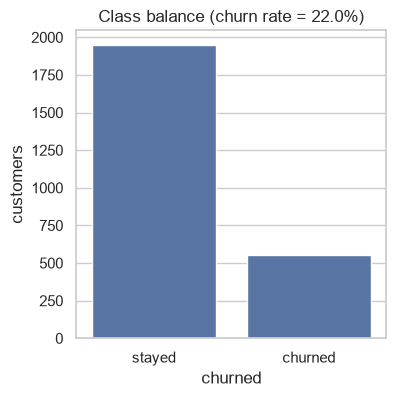

In [4]:
churn_counts = df['churned'].value_counts().sort_index()
churn_rate = df['churned'].mean()
print(f"Churn rate: {churn_rate:.1%}")

plt.figure(figsize=(4, 4))
sns.barplot(x=churn_counts.index.map({0: 'stayed', 1: 'churned'}), y=churn_counts.values)
plt.ylabel('customers')
plt.title(f'Class balance (churn rate = {churn_rate:.1%})')
plt.show()

## 3. Missing values

We deliberately injected NULLs into `total_charges` at the SQL level (brand-new customers who haven't been billed yet). This is exactly the kind of thing EDA should surface *before* it becomes a training-time surprise -- it's what tells us `features.py` needs an imputation step, not just a `dropna()`.

In [5]:
null_summary = df.isna().sum().to_frame('null_count')
null_summary['null_rate'] = (null_summary['null_count'] / len(df)).round(3)
null_summary[null_summary['null_count'] > 0]

,null_count,null_rate
total_charges,179,0.072


## 4. Distributions and summary statistics

`.describe()` gives min/max/quartiles for every numeric column -- a fast way to spot impossible values (negative tenure, a monthly charge of $0, etc.) before they reach the model.

In [6]:
df.describe()

,customer_id,tenure_months,monthly_charges,total_charges,support_ticket_count,churned
count,2500.00000,2500.00000,2500.000000,2321.000000,2500.000000,2500.000000
mean,1250.50000,36.37560,70.063720,2606.873542,0.702000,0.220400
std,721.83216,20.78802,24.817547,1820.122557,0.815759,0.414599
min,1.00000,1.00000,15.000000,44.030000,0.000000,0.000000
25%,625.75000,18.00000,52.730000,1133.240000,0.000000,0.000000
50%,1250.50000,36.00000,70.070000,2296.070000,1.000000,0.000000
75%,1875.25000,54.00000,86.012500,3760.260000,1.000000,0.000000
max,2500.00000,72.00000,150.000000,10151.210000,5.000000,1.000000


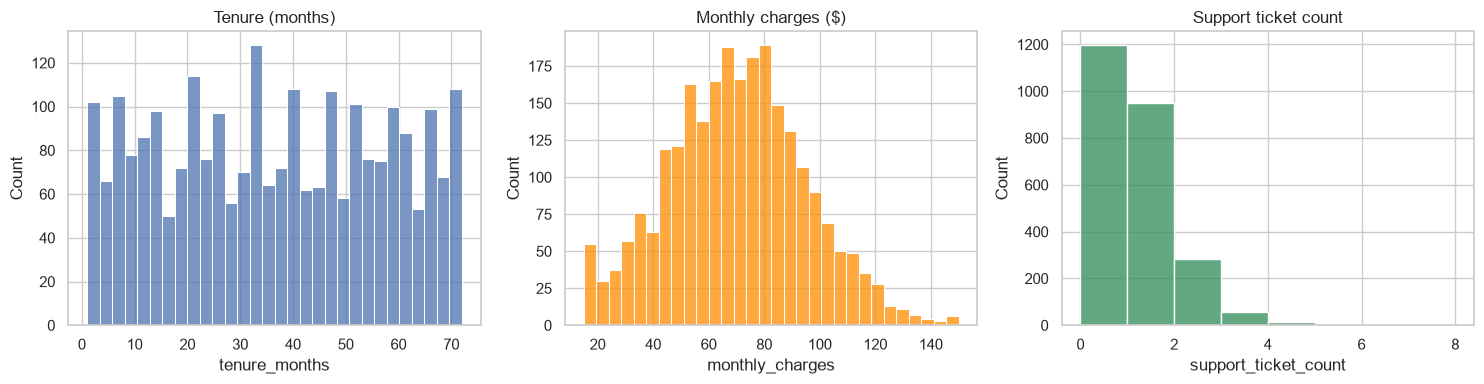

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['tenure_months'], bins=30, ax=axes[0])
axes[0].set_title('Tenure (months)')
sns.histplot(df['monthly_charges'], bins=30, ax=axes[1], color='darkorange')
axes[1].set_title('Monthly charges ($)')
sns.histplot(df['support_ticket_count'], bins=range(0, 9), ax=axes[2], color='seagreen')
axes[2].set_title('Support ticket count')
plt.tight_layout()
plt.show()

## 5. Churned vs. stayed -- how do the feature distributions differ?

This is the classification analogue of project 1's "price vs. sqft" scatter: instead of a continuous relationship, we're comparing two groups. If a feature looks identical between churned and stayed customers, it likely won't help the model separate them.

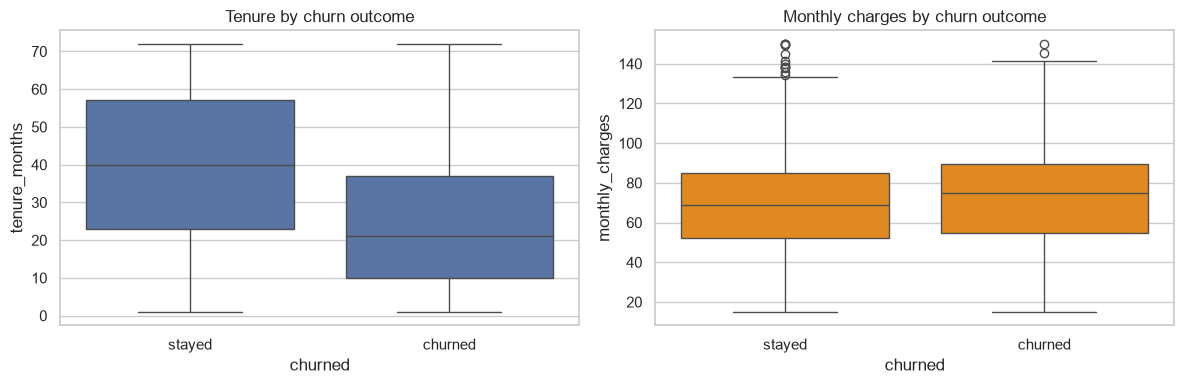

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='churned', y='tenure_months', ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['stayed', 'churned'])
axes[0].set_title('Tenure by churn outcome')
sns.boxplot(data=df, x='churned', y='monthly_charges', ax=axes[1], color='darkorange')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['stayed', 'churned'])
axes[1].set_title('Monthly charges by churn outcome')
plt.tight_layout()
plt.show()

As expected from how the synthetic data is generated (see `data_generation.py`): churners skew toward **shorter tenure** and **higher monthly charges** -- both were given negative/positive coefficients respectively in the ground-truth churn-probability formula.

## 6. Categorical breakdown: contract type

`contract_type` has only three values, which is what tells us one-hot encoding (not, say, treating it as an ordered number) is the right call in `features.py`.

In [9]:
contract_churn = df.groupby('contract_type')['churned'].agg(['count', 'mean']).rename(columns={'mean': 'churn_rate'}).sort_values('churn_rate', ascending=False)
contract_churn

,count,churn_rate
contract_type,,
month-to-month,1378,0.284470
one-year,733,0.178718
two-year,389,0.071979


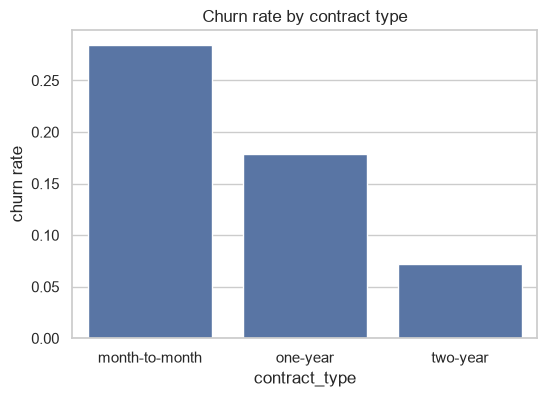

In [10]:
plt.figure(figsize=(6, 4))
order = contract_churn.index
sns.barplot(x=order, y=contract_churn['churn_rate'], order=order)
plt.ylabel('churn rate')
plt.title('Churn rate by contract type')
plt.show()

Month-to-month customers churn at a much higher rate than one- or two-year contract holders -- a strong, intuitive signal the model should pick up on.

## 7. Support tickets vs. churn

More support tickets should mean more friction with the product -- does the data show that?

In [11]:
ticket_churn = df.groupby('support_ticket_count')['churned'].agg(['count', 'mean']).rename(columns={'mean': 'churn_rate'})
ticket_churn

,count,churn_rate
support_ticket_count,,
0,1196,0.176421
1,948,0.237342
2,282,0.304965
3,56,0.375000
4,15,0.333333
5,3,1.000000


## 8. Correlation heatmap (numeric features only)

A correlation heatmap is a quick (linear-relationships-only) way to see which numeric features move with `churned`. It won't catch the non-linear/categorical effects above (like the contract-type breakdown), which is exactly why EDA needs both views.

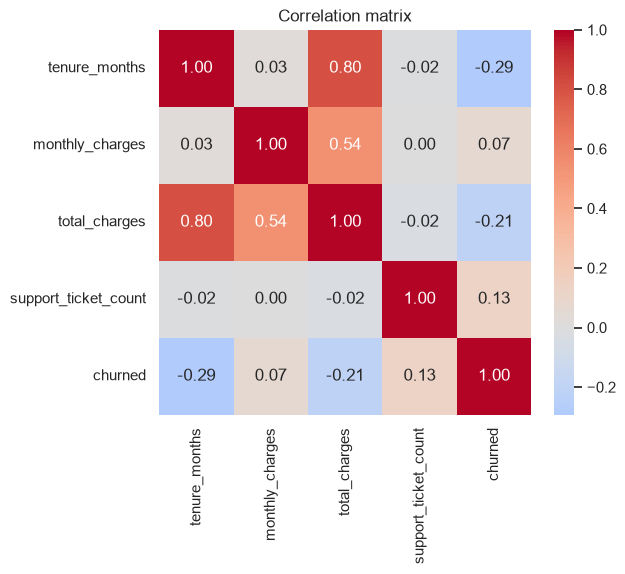

In [12]:
numeric_cols = ['tenure_months', 'monthly_charges', 'total_charges', 'support_ticket_count', 'churned']
corr = df[numeric_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

## Takeaways going into modeling

- `total_charges` needs imputation (~7% missing, concentrated in brand-new customers) -- handled by median imputation in `features.py`.
- The target is **imbalanced** (~20-25% churn) -- this rules out accuracy as the primary metric and is why `train.py` promotes on ROC-AUC instead (see the README's metrics section for the full argument).
- `tenure_months`, `monthly_charges`, and `contract_type` all show a visible relationship with churn, exactly as designed into `data_generation.py`'s `ChurnCoefficients`.
- `contract_type` is genuinely categorical (three unlabeled buckets, no natural order) -- one-hot encoding it, not label-encoding it, in `features.py` avoids implying a fake ranking.
- Next: `../README.md` walks through running `train.py`, which fits this preprocessing + a model together in one `Pipeline`, logs the run to MLflow, and promotes it to `Production` if it beats whatever's already there.